# WANDS: weighting product fields

**Question:** WANDS describes every product with five text fields. Does giving each field its own BM25
index and weight beat indexing all of them as one document, and which fields carry the signal?

| Field | What it holds | Avg. tokens |
|---|---|---|
| `product_name` | short product title | 6.5 |
| `category hierarchy` | category path, e.g. `Furniture / Living Room Furniture / Console Tables` | 8.3 |
| `product_description` | free-text description | 65.2 |
| `product_class` | product type, e.g. `Sofa & Console Tables` | 2.2 |
| `product_features` | `key : value` attributes such as color, material and style | 150.8 |

The remaining columns (`rating_count`, `average_rating`, `review_count`) are numbers, not text, so BM25
cannot index them; using them would be a separate ranking-signal experiment.

The tokenizer is **fixed (regex + Porter)** and every field gets its own BM25 index. Only the field
weights change:

$$s(q,d)=\sum_{f \in \text{fields}} w_f\,BM25_f(q,d).$$

We compare concatenated text, single fields, equal weights and tuned weights. To see which fields are
worth indexing, the same run also tunes a smaller field set: name, category and description only, without
the type label and the long attribute list. Note that this is a **sum of per-field BM25 scores**, each
with its own IDF and length normalization; it is **not BM25F**.

## 1. Setup and data

Run once if needed: `%pip install bm25s numpy pandas scipy nltk matplotlib`

We use the tab-separated `product.csv`, `query.csv` and `label.csv` files from
[WANDS](https://github.com/wayfair/WANDS). The paths below are checked in order; change `DATA_DIR` /
`DATA_ZIP` if your copy lives elsewhere. The ZIP is read in place, so no data or index is written to disk.

`FIELDS` lists every field to weight, and `SUBSET` is the smaller field set compared in the same run.
`product_features` is indexed as-is, so attribute keys such as `overallwidth` are indexed too; they appear
in most products and get a low IDF. The weight grid grows quickly with the number of fields: 4 levels and
5 fields give 781 distinct settings.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from functools import lru_cache
from itertools import product
import gc
import re

import bm25s
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer
from IPython.display import display

# Paths are relative to this notebook (retrieval/).
DATA_DIR = Path("../datasets/wands")  # extracted WANDS folder
DATA_ZIP = Path("../datasets.zip")    # or a zip containing datasets/wands/*.csv
# All five text fields in WANDS; the numeric columns (ratings, review counts) are not text.
FIELDS = ["product_name", "category hierarchy", "product_description",
          "product_class", "product_features"]
# A smaller field set tuned in the same run: no type label and no attribute list.
SUBSET = ["product_name", "category hierarchy", "product_description"]
LEVELS = (0, 1, 2, 4)  # 0 drops the field; a common scale factor does not change the ranking
SEEDS = (0, 1, 2, 3, 4)
BATCH_SIZE, K = 16, 100
BM25_PARAMS = dict(method="lucene", k1=1.2, b=0.75)
assert FIELDS and len(set(FIELDS)) == len(FIELDS)
assert set(SUBSET) < set(FIELDS), "SUBSET must be a proper subset of FIELDS."


def load_table(name):
    if (DATA_DIR / name).is_file():
        return pd.read_csv(DATA_DIR / name, sep="\t")
    if DATA_ZIP.is_file():
        with ZipFile(DATA_ZIP) as z, z.open(f"datasets/wands/{name}") as f:
            return pd.read_csv(f, sep="\t")
    raise FileNotFoundError(f"{name} not found: set DATA_DIR or DATA_ZIP.")


products = load_table("product.csv")
queries = load_table("query.csv")
labels = load_table("label.csv")
assert set(FIELDS) <= set(products.columns), "FIELDS contains an unknown column."
products[FIELDS] = products[FIELDS].fillna("").astype(str)
assert products.product_id.is_unique and queries.query_id.is_unique
assert len(products) >= K
pos = {str(pid): i for i, pid in enumerate(products.product_id)}
labels = labels.assign(
    qid=labels.query_id.astype(str),
    doc=labels.product_id.astype(str).map(pos),
    grade=labels.label.map({"Exact": 2, "Partial": 1, "Irrelevant": 0}),
)
assert labels[["doc", "grade"]].notna().all().all()
# Keep the highest grade if a (query, product) pair is labeled more than once.
labels = labels.groupby(["qid", "doc"], as_index=False).grade.max()
qrels = {qid: dict(zip(g.doc.astype(int), g.grade.astype(int)))
         for qid, g in labels.groupby("qid")}
# Only queries with at least one relevant (Exact or Partial) product can be evaluated.
queries = queries[queries.query_id.astype(str).map(
    lambda q: any(v > 0 for v in qrels.get(q, {}).values()))].reset_index(drop=True)
grades = [qrels[str(q)] for q in queries.query_id]
assert len(queries) >= 4
print(f"{len(products):,} products; {len(queries)} evaluable queries")
display(pd.DataFrame({"Field": FIELDS,
    "Empty (%)": [100 * products[f].str.strip().eq("").mean() for f in FIELDS],
    "Example": [products[f].iloc[0][:70] for f in FIELDS]}).round(2))

42,994 products; 479 evaluable queries


,Field,Empty (%),Example
0,product_name,0.00,solid wood platform bed
1,category hierarchy,3.62,Furniture / Bedroom Furniture / Beds & Headboa...
2,product_description,13.97,"good , deep sleep can be quite difficult to ha..."
3,product_class,6.63,Beds
4,product_features,0.00,overallwidth-sidetoside:64.7|dsprimaryproducts...


## 2. Same tokenizer, separate field indexes

Every field uses the same regex + Porter tokenizer and Lucene BM25 parameters (k1 = 1.2, b = 0.75).
Empty field values are kept so that a product sits on the same row in every index.
Two concatenated baselines are indexed as well: all fields in one document, and `SUBSET` in one document.
Each query is scored against **all** products; there is no fusion step that depends on a top-k candidate pool.

In [2]:
porter = PorterStemmer()

@lru_cache(maxsize=200_000)
def stem(word):
    return porter.stem(word)


def tokenize(text):
    return [stem(t) for t in re.findall(r"\w+", text.lower())]


query_tokens = [tokenize(q) for q in queries["query"].astype(str)]


class FieldScorer:
    """BM25 for one field, scored as a sparse (query x term) @ (term x doc) product.

    Reuses bm25s' precomputed per-term document scores, so a whole batch of
    queries is scored with a single sparse matrix multiplication.
    """

    def __init__(self, token_lists, probe_queries):
        index = bm25s.BM25(**BM25_PARAMS)
        index.index(token_lists, show_progress=False)
        s = index.scores
        self.vocab = index.vocab_dict
        self.matrix = sp.csc_matrix(
            (s["data"], s["indices"], s["indptr"]),
            shape=(len(token_lists), len(s["indptr"]) - 1),
        ).T.tocsr()
        self.avg_len = np.mean([len(t) for t in token_lists])
        # Sanity check against the library: repeated terms, out-of-vocabulary and empty queries.
        probe = [probe_queries[0], probe_queries[0] * 2, ["__oov_probe__"], []]
        ref = np.stack([index.get_scores(t) if t else np.zeros(len(token_lists)) for t in probe])
        assert np.allclose(self.score(probe), ref, atol=1e-4)

    def score(self, token_lists):
        # Repeated query terms are counted twice, matching bm25s.get_scores.
        rows, cols = [], []
        for i, tokens in enumerate(token_lists):
            for t in tokens:
                j = self.vocab.get(t)
                if j is not None:
                    rows.append(i)
                    cols.append(j)
        q = sp.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)),
                          shape=(len(token_lists), self.matrix.shape[0]))
        return (q @ self.matrix).toarray()


CONCAT_ALL, CONCAT_SUBSET = "concat_all", "concat_subset"
sources = {**{f: products[f] for f in FIELDS},
           CONCAT_ALL: products[FIELDS].agg(" ".join, axis=1),
           CONCAT_SUBSET: products[SUBSET].agg(" ".join, axis=1)}
scorers, stats = {}, []
for name, texts in sources.items():
    scorers[name] = FieldScorer([tokenize(t) for t in texts], query_tokens)
    stats.append({"Index": name, "Avg. tokens": scorers[name].avg_len,
                  "Vocabulary": len(scorers[name].vocab)})
    print("Indexed:", name)
    gc.collect()
display(pd.DataFrame(stats).round(1))

Indexed: product_name


Indexed: category hierarchy


Indexed: product_description
Indexed: product_class


Indexed: product_features


Indexed: concat_all


Indexed: concat_subset


,Index,Avg. tokens,Vocabulary
0,product_name,6.5,25436
1,category hierarchy,8.3,1117
2,product_description,65.2,19827
3,product_class,2.2,629
4,product_features,150.8,22424
5,concat_all,233.1,51267
6,concat_subset,80.0,36756


## 3. Weight sweep and metrics

We sweep each weight over `{0, 1, 2, 4}` in `FIELDS` order. Vectors that are equal up to a common factor
rank identically, so they are deduplicated. Single-field, equal-weight and leave-one-field-out
(ablation) settings are all part of the grid, and so is every setting that gives the fields outside
`SUBSET` weight 0, which is the grid for the smaller field set. Scores are **not** normalized, so a weight
should be read together with the scale of that field's BM25 scores. Repeating a field's text is not the
same thing: it also changes term frequency and document length.

**nDCG@10:** Exact=2, Partial=1, gain `2**grade - 1`.
**MRR@10:** Exact only; queries with no Exact product are left out of the average.
**Recall@10/@100:** Exact + Partial. Unlabeled products count as irrelevant.
Ties are broken by the lower product row number; products with a zero score are not returned.

Scoring all settings takes a few minutes on a laptop.

In [3]:
# Weights are always in FIELDS order.
weight_grid = sorted({tuple(np.array(w, dtype=float) / max(w))
                      for w in product(LEVELS, repeat=len(FIELDS)) if max(w) > 0})
BASELINE, EQUAL = CONCAT_SUBSET, "equal"  # baseline: the stronger concatenation (see section 4)
configs = {CONCAT_ALL: None, CONCAT_SUBSET: None, EQUAL: np.ones(len(FIELDS))}
configs.update({f"w{i:03d}": np.array(w) for i, w in enumerate(weight_grid)
                if len(set(w)) > 1})  # the all-equal vector is already EQUAL
TUNABLE = [s for s in configs if configs[s] is not None]
# Settings that give every field outside SUBSET weight 0: the smaller field set's grid.
outside = np.array([f not in SUBSET for f in FIELDS])
SUBSET_ONLY = [s for s in TUNABLE if not configs[s][outside].any()]
print(f"{len(TUNABLE)} weight settings ({len(SUBSET_ONLY)} use only {SUBSET}); "
      f"field order: {FIELDS}")


def topk(scores, k=K):
    # Resolve ties at the cutoff deterministically; pad missing results with -1.
    ranked = np.full((len(scores), k), -1, dtype=np.int32)
    for i, row in enumerate(scores):
        cutoff = np.partition(row, len(row) - k)[len(row) - k]
        above = np.flatnonzero(row > cutoff)
        tied = np.flatnonzero(row == cutoff)[:k - len(above)]
        ids = np.concatenate([above, tied])
        ids = ids[np.lexsort((ids, -row[ids]))]
        ids = ids[row[ids] > 0]
        ranked[i, :len(ids)] = ids
    return ranked


discounts = 1 / np.log2(np.arange(2, 12))
n_rel = np.array([sum(v > 0 for v in g.values()) for g in grades])
has_exact = np.array([2 in g.values() for g in grades])
idcg = np.array([np.dot(2.0 ** np.array(sorted(g.values(), reverse=True)[:10]) - 1,
                       discounts[:min(10, len(g))]) for g in grades])
METRICS = ["nDCG@10", "MRR@10", "Recall@10", "Recall@100"]


def evaluate(ranked):
    """Per-query metrics; MRR@10 is NaN for queries without an Exact product."""
    g = np.array([[rel.get(int(d), 0) for d in row] for row, rel in zip(ranked, grades)])
    exact = g[:, :10] == 2
    return {
        "nDCG@10": ((2.0 ** g[:, :10] - 1) * discounts).sum(1) / idcg,
        "MRR@10": np.where(has_exact, np.where(exact.any(1), 1 / (exact.argmax(1) + 1), 0), np.nan),
        "Recall@10": (g[:, :10] > 0).sum(1) / n_rel,
        "Recall@100": (g > 0).sum(1) / n_rel,
    }


# Score each field once per batch, then combine the cached scores for every weight setting.
rankings = {s: [] for s in configs}
for start in range(0, len(queries), BATCH_SIZE):
    batch = query_tokens[start:start + BATCH_SIZE]
    field_scores = [scorers[f].score(batch) for f in FIELDS]
    for concat in (CONCAT_ALL, CONCAT_SUBSET):
        rankings[concat].append(topk(scorers[concat].score(batch)))
    for system in TUNABLE:
        scores = np.zeros_like(field_scores[0])
        for weight, values in zip(configs[system], field_scores):
            if weight > 0:
                scores += weight * values
        rankings[system].append(topk(scores))
rankings = {s: np.concatenate(parts) for s, parts in rankings.items()}
per_query = {s: evaluate(r) for s, r in rankings.items()}

781 weight settings (37 use only ['product_name', 'category hierarchy', 'product_description']); field order: ['product_name', 'category hierarchy', 'product_description', 'product_class', 'product_features']


## 4. Comparison without selection bias

We use **5 seeds × two-way 2-fold** cross-validation. Each time, the weights are chosen by mean nDCG@10
on one half of the queries and measured on the other half; then the roles swap. Every query therefore
gets an out-of-fold (OOF) score from weights it did not help choose. Tuning is done twice on the same
splits: over all settings, and over the settings that use only `SUBSET`. The concatenated baselines and
equal weights are fixed references with nothing to tune.

Δ values are measured against the `SUBSET` concatenation, the stronger of the two concatenated baselines,
so the reported gains are conservative. The seeds reuse the same queries, so the seed standard deviation
only shows sensitivity to the split; it is **not** a confidence interval. For that, the cell also reports
paired bootstrap 95% CIs over queries (OOF scores averaged over seeds). The last row compares the two
tuned systems directly: what `product_class` and `product_features` add when every field can be weighted.

,nDCG@10,MRR@10,Recall@10,Recall@100,Δ nDCG (pp),nDCG seed std
Method,,,,,,
"Concatenated text, all 5 fields",0.6687,0.6979,0.0591,0.3734,-1.6435,0.0000
"Concatenated text, 3 fields",0.6852,0.7068,0.0602,0.3756,0.0000,0.0000
"Equal weights, all 5 fields",0.6861,0.6409,0.0613,0.3859,0.0967,0.0000
"Tuned, 3 fields (OOF)",0.7142,0.6856,0.0638,0.4082,2.8987,0.0015
"Tuned, all 5 fields (OOF)",0.7188,0.6952,0.0640,0.4114,3.3633,0.0037


,Pool,product_name,category hierarchy,product_description,product_class,product_features,Times selected
0,"Tuned, 3 fields (OOF)",1.0,0.50,0.25,0.00,0.00,7
1,"Tuned, 3 fields (OOF)",1.0,0.50,0.50,0.00,0.00,3
4,"Tuned, all 5 fields (OOF)",1.0,0.50,0.25,0.25,0.25,6
2,"Tuned, all 5 fields (OOF)",1.0,0.25,0.25,0.25,0.25,1
3,"Tuned, all 5 fields (OOF)",1.0,0.25,0.50,0.50,0.25,1
5,"Tuned, all 5 fields (OOF)",1.0,0.50,0.25,0.25,0.50,1
6,"Tuned, all 5 fields (OOF)",1.0,0.50,0.25,0.50,0.00,1


,Δ nDCG (pp),95% CI low,95% CI high,Wins,Losses
Comparison,,,,,
"Concatenated text, all 5 fields vs. Concatenated text, 3 fields",-1.64,-2.96,-0.29,149,203
"Equal weights, all 5 fields vs. Concatenated text, 3 fields",0.10,-1.67,1.94,185,184
"Tuned, 3 fields (OOF) vs. Concatenated text, 3 fields",2.90,1.22,4.58,205,166
"Tuned, all 5 fields (OOF) vs. Concatenated text, 3 fields",3.36,1.66,5.11,212,158
"Tuned, all 5 fields (OOF) vs. Tuned, 3 fields (OOF)",0.46,-0.16,1.11,166,139


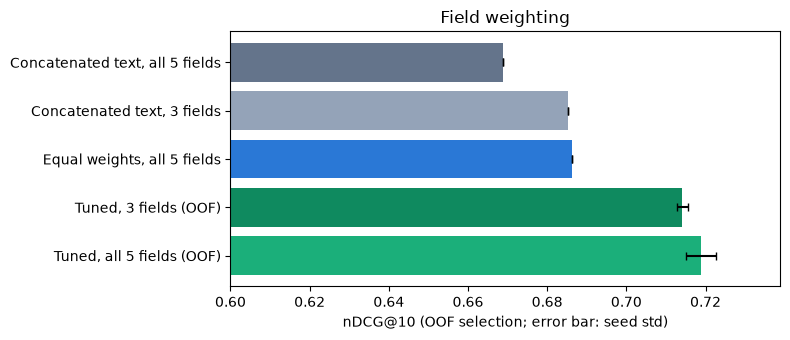

In [4]:
n_sub, n_all = len(SUBSET), len(FIELDS)
POOLS = {"oof_subset": SUBSET_ONLY, "oof_all": TUNABLE}
NAMES = {CONCAT_ALL: f"Concatenated text, all {n_all} fields",
         CONCAT_SUBSET: f"Concatenated text, {n_sub} fields",
         EQUAL: f"Equal weights, all {n_all} fields",
         "oof_subset": f"Tuned, {n_sub} fields (OOF)",
         "oof_all": f"Tuned, all {n_all} fields (OOF)"}
cv_rows, selections = [], []
oof_runs = {pool: {} for pool in POOLS}
chosen_runs = {pool: {} for pool in POOLS}
for seed in SEEDS:
    perm = np.random.default_rng(seed).permutation(len(queries))
    folds = np.array_split(perm, 2)
    for pool, systems in POOLS.items():
        oof = {m: np.full(len(queries), np.nan) for m in METRICS}
        chosen = np.empty(len(queries), dtype=object)
        for fold in range(2):
            tune, held = folds[fold], folds[1 - fold]
            best = max(systems, key=lambda s: per_query[s]["nDCG@10"][tune].mean())
            selections.append({"Pool": NAMES[pool], "Seed": seed, "Fold": fold,
                               **dict(zip(FIELDS, configs[best]))})
            chosen[held] = best
            for m in METRICS:
                oof[m][held] = per_query[best][m][held]
        oof_runs[pool][seed], chosen_runs[pool][seed] = oof, chosen
    results = {s: per_query[s] for s in (CONCAT_ALL, CONCAT_SUBSET, EQUAL)}
    results.update({pool: oof_runs[pool][seed] for pool in POOLS})
    for key, values in results.items():
        cv_rows.append({"Seed": seed, "Method": NAMES[key],
                        **{m: np.nanmean(values[m]) for m in METRICS},
                        "Δ nDCG (pp)": 100 * (values["nDCG@10"] - per_query[BASELINE]["nDCG@10"]).mean()})
cv = pd.DataFrame(cv_rows)
summary = cv.groupby("Method", sort=False)[METRICS + ["Δ nDCG (pp)"]].mean()
summary["nDCG seed std"] = cv.groupby("Method")["nDCG@10"].std()
display(summary.round(4))
selection_df = pd.DataFrame(selections)
display(selection_df.groupby(["Pool", *FIELDS]).size().rename("Times selected").reset_index()
        .sort_values(["Pool", "Times selected"], ascending=[True, False]))

# Paired bootstrap over queries: is each nDCG@10 change larger than query-sampling noise?
ndcg = {s: per_query[s]["nDCG@10"] for s in (CONCAT_ALL, CONCAT_SUBSET, EQUAL)}
ndcg.update({pool: np.mean([oof_runs[pool][s]["nDCG@10"] for s in SEEDS], axis=0) for pool in POOLS})
rng = np.random.default_rng(0)
boot_idx = rng.integers(0, len(queries), size=(10_000, len(queries)))
ci_rows = []
for a, b in [(CONCAT_ALL, BASELINE), (EQUAL, BASELINE), ("oof_subset", BASELINE),
             ("oof_all", BASELINE), ("oof_all", "oof_subset")]:
    diff = 100 * (ndcg[a] - ndcg[b])
    lo, hi = np.percentile(diff[boot_idx].mean(1), [2.5, 97.5])
    ci_rows.append({"Comparison": f"{NAMES[a]} vs. {NAMES[b]}", "Δ nDCG (pp)": diff.mean(),
                    "95% CI low": lo, "95% CI high": hi,
                    "Wins": (diff > 0).sum(), "Losses": (diff < 0).sum()})
display(pd.DataFrame(ci_rows).set_index("Comparison").round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(summary.index[::-1], summary["nDCG@10"][::-1], xerr=summary["nDCG seed std"][::-1],
        color=["#1baf7a", "#0f8a5f", "#2a78d6", "#94a3b8", "#64748b"], capsize=3)
ax.set(xlabel="nDCG@10 (OOF selection; error bar: seed std)", title="Field weighting",
       xlim=(0.6, summary["nDCG@10"].max() + 0.02))
plt.tight_layout()
plt.show()

## 5. Which field contributes?

The single-field and ablation table below is **exploratory**: it shows fixed settings evaluated on all
queries, so it must not be read as a tuned result like the OOF table above. In each ablation, the
removed field gets weight 0 and the remaining fields keep equal weights.

After the table, we look at the queries with the largest gains and losses of the all-field OOF system
against the baseline for the first seed, each ranked with its own held-out weights, and show the top 3
results of both.

In [5]:
ablations = {NAMES[s]: s for s in (CONCAT_ALL, CONCAT_SUBSET, EQUAL)}
for i, field in enumerate(FIELDS):
    single = np.zeros(len(FIELDS)); single[i] = 1
    without = np.ones(len(FIELDS)); without[i] = 0
    for name, weights in [(f"Only {field}", single), (f"Without {field}", without)]:
        match = next((s for s in TUNABLE if np.array_equal(configs[s], weights)), None)
        if match is not None:
            ablations[name] = match
display(pd.DataFrame([
    {"Experiment": name, **{m: np.nanmean(per_query[s][m]) for m in METRICS}}
    for name, s in ablations.items()
]).set_index("Experiment").round(4))

# OOF gains/losses for the first seed: every query uses its own held-out weights.
SHOW = ["product_name", "product_class", "category hierarchy"]  # short fields that fit in a table
seed, pool = SEEDS[0], "oof_all"
delta = oof_runs[pool][seed]["nDCG@10"] - per_query[BASELINE]["nDCG@10"]
for title, indices in [("Largest gains", np.argsort(-delta)),
                       ("Largest losses", np.argsort(delta))]:
    print("\n" + title)
    for qi in indices[:2]:
        system = chosen_runs[pool][seed][qi]
        print(f"\n{queries.iloc[qi]['query']} | Δ nDCG={delta[qi]:+.3f}")
        print("Weights:", dict(zip(FIELDS, configs[system].tolist())))
        rows = []
        for name, s in [("concat (3 fields)", BASELINE), ("OOF (all fields)", system)]:
            for rank, d in enumerate(rankings[s][qi, :3], 1):
                if d >= 0:
                    rows.append({"Method": name, "Rank": rank, "Label": grades[qi].get(int(d), 0),
                                 **{f: products.iloc[d][f][:70] for f in SHOW}})
        display(pd.DataFrame(rows))

,nDCG@10,MRR@10,Recall@10,Recall@100
Experiment,,,,
"Concatenated text, all 5 fields",0.6687,0.6979,0.0591,0.3734
"Concatenated text, 3 fields",0.6852,0.7068,0.0602,0.3756
"Equal weights, all 5 fields",0.6861,0.6409,0.0613,0.3859
Only product_name,0.6671,0.6576,0.0617,0.3856
Without product_name,0.5736,0.5135,0.0504,0.3115
Only category hierarchy,0.2671,0.1673,0.0241,0.1730
Without category hierarchy,0.6869,0.6472,0.0614,0.3842
Only product_description,0.5297,0.5256,0.0469,0.2369
Without product_description,0.6657,0.6359,0.0595,0.3844



Largest gains

olive green console table | Δ nDCG=+0.890
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.5}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,0,george oliver mid-century tv stand with 2 stor...,TV Stands & Entertainment Centers,Furniture / Living Room Furniture / TV Stands ...
1,concat (3 fields),2,0,george oliver mid-century tv stand with 2 stor...,TV Stands & Entertainment Centers,Furniture / Living Room Furniture / TV Stands ...
2,concat (3 fields),3,1,durdham park console table,Sofa & Console Tables,Furniture / Living Room Furniture / Console Ta...
3,OOF (all fields),1,1,bouldin console table sofa table console tables,Sofa & Console Tables,Furniture / Living Room Furniture / Console Ta...
4,OOF (all fields),2,1,olive coffee table,Coffee & Cocktail Tables,Furniture / Living Room Furniture / Coffee Tab...
5,OOF (all fields),3,1,fabius console table,Sofa & Console Tables,Furniture / Living Room Furniture / Console Ta...



outdoor sectional doning | Δ nDCG=+0.767
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.5}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,0,caspian patio sectional with cushion,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
1,concat (3 fields),2,0,arshleen patio sofa with cushions,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
2,concat (3 fields),3,0,murph teal/gray indoor/outdoor area rug,Area Rugs,Rugs / Area Rugs
3,OOF (all fields),1,1,tahoe outdoor wicker patio sectional with cush...,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
4,OOF (all fields),2,1,montclaire outdoor patio sectional with cushions,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
5,OOF (all fields),3,1,catalina outdoor right arm sectional piece wit...,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...



Largest losses

glass doors for bath | Δ nDCG=-0.844
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.25}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,2,fluence 59.63 '' x 58.31 '' bypass bath door,Shower & Tub Doors,Home Improvement / Bathroom Remodel & Bathroom...
1,concat (3 fields),2,2,fluence 59.63 '' x 58.31 '' bypass bath door w...,Shower & Tub Doors,Home Improvement / Bathroom Remodel & Bathroom...
2,concat (3 fields),3,2,fluence 52 '' x 63 '' bypass bath door with cl...,Shower & Tub Doors,Home Improvement / Bathroom Remodel & Bathroom...
3,OOF (all fields),1,0,glass wood french doors,Interior Doors,Home Improvement / Doors & Door Hardware / Int...
4,OOF (all fields),2,0,lucia glass french doors,Interior Doors,Home Improvement / Doors & Door Hardware / Int...
5,OOF (all fields),3,0,quadro glass french doors,Interior Doors,Home Improvement / Doors & Door Hardware / Int...



bathroom vanity knobs | Δ nDCG=-0.708
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.25}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,2,damask™ mushroom knob,Cabinet and Drawer Knobs,Home Improvement / Hardware / Cabinet Hardware...
1,concat (3 fields),2,2,deco 1/4 '' length square knob,Cabinet and Drawer Knobs,Home Improvement / Hardware / Cabinet Hardware...
2,concat (3 fields),3,2,deco 1 1/4 '' length square knob,Cabinet and Drawer Knobs,Home Improvement / Hardware / Cabinet Hardware...
3,OOF (all fields),1,0,esterly 32 '' single bathroom vanity,Vanities,Home Improvement / Bathroom Remodel & Bathroom...
4,OOF (all fields),2,0,ruvalcaba 32 '' single bathroom vanity set,Vanities,Home Improvement / Bathroom Remodel & Bathroom...
5,OOF (all fields),3,0,pichardo transitional 84 '' double bathroom va...,Vanities,Home Improvement / Bathroom Remodel & Bathroom...


### Reading the results

- **Concatenated → equal fields:** the effect of splitting the fields, which changes IDF and length normalization.
- **Equal fields → tuned OOF:** what weight selection adds on top. If nDCG goes up while Recall@100 goes
  down, the candidate coverage may be shrinking.
- **Tuned, 3 fields → tuned, all fields:** what `product_class` and `product_features` add when every field
  can be weighted.
- If the selected weights change across seeds/folds, any claim of a single "best" weight is weak.
- Treat the explanations below as hypotheses to test on example queries, not as conclusions.

No improvement is assumed. The results depend on these queries and labels; other tokenizers, per-field
`b` tuning, BM25F and cleaning the `product_features` keys are out of scope for this experiment.
Re-run the notebook if you change `FIELDS`.

**Results of the saved run:** 42,994 products, 479 queries with at least one relevant label and 781 weight
settings (37 of them use only name, category and description). All Δ values are nDCG@10 changes against
the three-field concatenated text, with paired bootstrap 95% CIs.

- **Tuned weights over all five fields are the best system:** nDCG@10 **0.7188** (+3.36 pp, CI
  **[+1.66, +5.11]**), Recall@100 **0.4114**; 212 queries improved and 158 got worse. The most common choice
  (6 of 10 folds) was `(name=1, category=0.5, description=0.25, class=0.25, features=0.25)`. The name always
  had the top weight, and every other field stayed at a quarter or half of it.
- **One document with all the text is the worst way to use it:** concatenating all five fields gives
  **0.6687**, 1.64 pp *below* the three-field concatenation (CI **[−2.96, −0.29]**). The attribute list
  nearly triples the document (80 → 233 tokens), so length normalization dilutes name matches.
- **Splitting without weighting does not help:** five equal weights give **0.6861** (+0.10 pp, CI
  **[−1.67, +1.94]**). At equal weight, removing `product_class` even scores higher (0.6906).
- **The weights do the work:** tuning over name, category and description alone already gives **0.7142**
  (+2.90 pp, CI **[+1.22, +4.58]**; `(1, 0.5, 0.25)` in 7 of 10 folds). Class and features add **+0.46 pp** on
  top (CI **[−0.16, +1.11]**, 166 wins and 139 losses), which is not distinguishable from query-sampling
  noise. The larger grid also makes the tuning less stable (seed std 0.0015 → 0.0037).
- **MRR@10:** no setting in the whole 781-setting grid beats the three-field concatenation (0.7068); the best
  reaches 0.7037. Tuned for nDCG, the all-field system scores 0.6952 and the three-field one 0.6856.
- **Single fields:** `product_name` is the strongest (0.6671) and removing it costs the most. The class
  (0.2393) and the category (0.2671) are weak alone and largely repeat each other; the features reach 0.3709.
- **Failure mode:** the largest losses (*"bathroom vanity knobs"* → vanities, *"glass doors for bath"* →
  French doors) come from a strong name match on a modifier beating the product type the user asked for.
  `product_class` holds the right type (`Cabinet and Drawer Knobs`, `Shower & Tub Doors`), but a low-weighted
  lexical match on it cannot outweigh the name.
- Recall@10 stays near 0.06 for every method because many WANDS queries have dozens or hundreds of relevant
  products; it is only useful for comparing methods with each other.

These numbers come from the saved run; re-generate the tables if the data or settings change.
